Shape: (178, 13)
Classes: {np.str_('class_0'): np.int64(59), np.str_('class_1'): np.int64(71), np.str_('class_2'): np.int64(48)}

KNN (k=5) accuracy: 0.9333

Classification report:
               precision    recall  f1-score   support

     class_0       1.00      1.00      1.00        15
     class_1       0.94      0.89      0.91        18
     class_2       0.85      0.92      0.88        12

    accuracy                           0.93        45
   macro avg       0.93      0.94      0.93        45
weighted avg       0.94      0.93      0.93        45



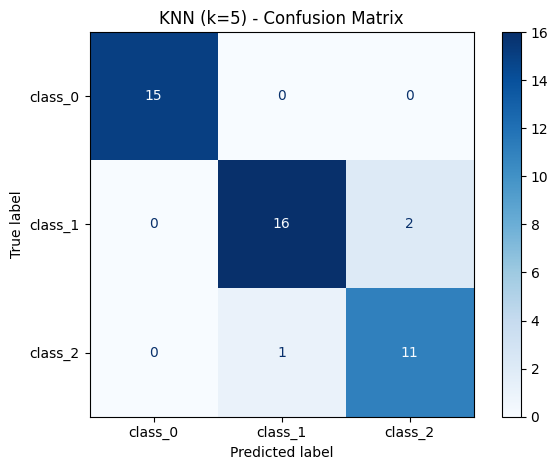

Accuracy WITHOUT scaling: 0.7778  |  WITH scaling: 0.9333


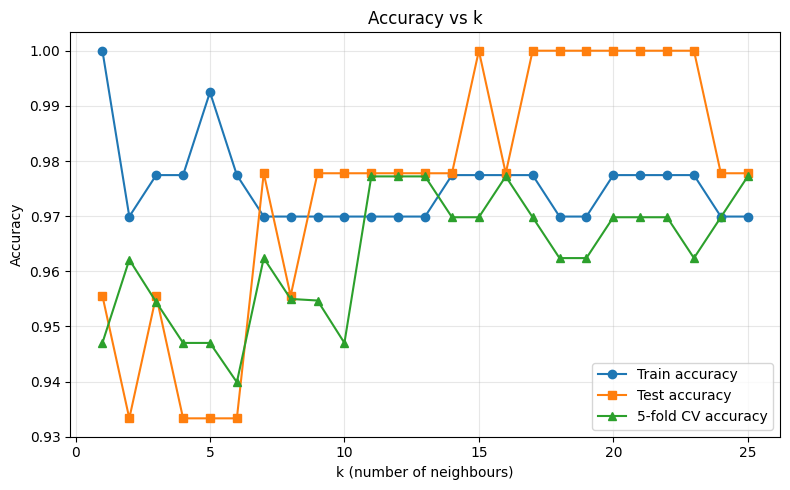


Best k by cross-validation: 11 (CV accuracy = 0.9772)

Best parameters: {'metric': 'manhattan', 'n_neighbors': 6, 'weights': 'uniform'}
Best CV score  : 0.9923
Test accuracy with tuned model: 0.9778


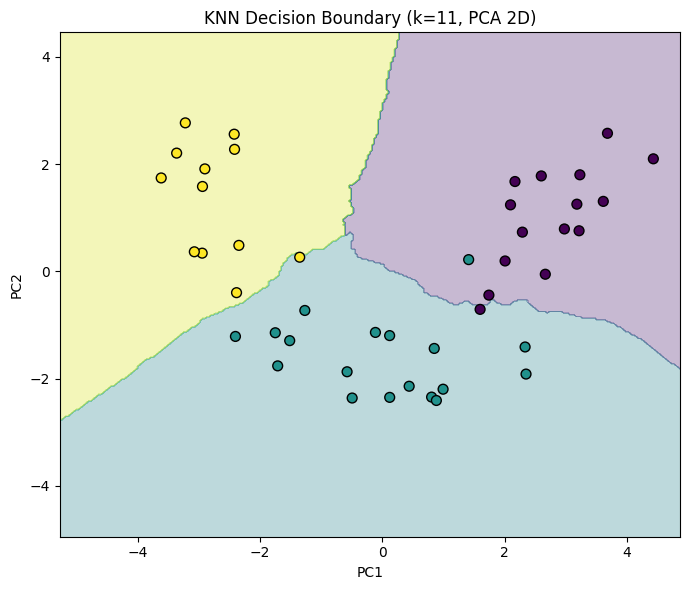


Scratch KNN accuracy      : 0.9333
Scikit-learn KNN accuracy : 0.9333

Prediction for first sample: class_0

Conclusion: KNN classifies a point by majority vote of its k nearest neighbours. Feature scaling and a well-chosen k are key to good accuracy.


In [ ]:
"""
Assignment 5: Apply the KNN algorithm for classification.

Steps:
  1. Load dataset (Wine: 13 features, 3 classes)
  2. Scale features (KNN is distance based, so scaling is essential)
  3. Train KNN and evaluate
  4. Choose best k (accuracy vs k, cross-validation)
  5. Tune k, distance metric and weights with GridSearchCV
  6. Decision boundary plot (2 features)
  7. KNN from scratch

Install: pip install numpy pandas matplotlib seaborn scikit-learn
"""

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from collections import Counter
from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, cross_val_score,
                                     GridSearchCV)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (accuracy_score, classification_report,
                             confusion_matrix, ConfusionMatrixDisplay)

# ------------------------------------------------------------------
# 1. Load data
# ------------------------------------------------------------------
wine = load_wine(as_frame=True)
X, y = wine.data, wine.target
print("Shape:", X.shape)
print("Classes:", dict(zip(wine.target_names, np.bincount(y))))

# ------------------------------------------------------------------
# 2. Split and scale (fit scaler on train only to avoid data leakage)
# ------------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

# ------------------------------------------------------------------
# 3. Train a basic KNN (k = 5)
# ------------------------------------------------------------------
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_s, y_train)
y_pred = knn.predict(X_test_s)

print("\nKNN (k=5) accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("\nClassification report:\n",
      classification_report(y_test, y_pred, target_names=wine.target_names))

ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred),
                       display_labels=wine.target_names).plot(cmap="Blues")
plt.title("KNN (k=5) - Confusion Matrix")
plt.tight_layout()
plt.show()

# Effect of scaling
raw_acc = accuracy_score(
    y_test, KNeighborsClassifier(5).fit(X_train, y_train).predict(X_test))
print(f"Accuracy WITHOUT scaling: {raw_acc:.4f}  |  WITH scaling: "
      f"{accuracy_score(y_test, y_pred):.4f}")

# ------------------------------------------------------------------
# 4. Choose best k using train/test accuracy and cross-validation
# ------------------------------------------------------------------
k_values = range(1, 26)
train_acc, test_acc, cv_acc = [], [], []

for k in k_values:
    m = KNeighborsClassifier(n_neighbors=k).fit(X_train_s, y_train)
    train_acc.append(m.score(X_train_s, y_train))
    test_acc.append(m.score(X_test_s, y_test))
    cv_acc.append(cross_val_score(m, X_train_s, y_train, cv=5).mean())

plt.figure(figsize=(8, 5))
plt.plot(k_values, train_acc, "o-", label="Train accuracy")
plt.plot(k_values, test_acc, "s-", label="Test accuracy")
plt.plot(k_values, cv_acc, "^-", label="5-fold CV accuracy")
plt.xlabel("k (number of neighbours)")
plt.ylabel("Accuracy")
plt.title("Accuracy vs k")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

best_k = list(k_values)[int(np.argmax(cv_acc))]
print(f"\nBest k by cross-validation: {best_k} (CV accuracy = {max(cv_acc):.4f})")

# ------------------------------------------------------------------
# 5. Hyperparameter tuning with GridSearchCV
# ------------------------------------------------------------------
param_grid = {
    "n_neighbors": list(range(1, 21)),
    "weights": ["uniform", "distance"],
    "metric": ["euclidean", "manhattan", "minkowski"],
}
grid = GridSearchCV(KNeighborsClassifier(), param_grid, cv=5, n_jobs=-1)
grid.fit(X_train_s, y_train)

print("\nBest parameters:", grid.best_params_)
print("Best CV score  :", round(grid.best_score_, 4))
best_model = grid.best_estimator_
print("Test accuracy with tuned model:",
      round(accuracy_score(y_test, best_model.predict(X_test_s)), 4))

# ------------------------------------------------------------------
# 6. Decision boundary (reduce to 2D with PCA for plotting)
# ------------------------------------------------------------------
pca = PCA(n_components=2).fit(X_train_s)
X_train_2d = pca.transform(X_train_s)
X_test_2d = pca.transform(X_test_s)

knn_2d = KNeighborsClassifier(n_neighbors=best_k).fit(X_train_2d, y_train)

x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300),
                     np.linspace(y_min, y_max, 300))
Z = knn_2d.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(7, 6))
plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")
plt.scatter(X_test_2d[:, 0], X_test_2d[:, 1], c=y_test,
            cmap="viridis", edgecolor="k", s=50)
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.title(f"KNN Decision Boundary (k={best_k}, PCA 2D)")
plt.tight_layout()
plt.show()

# ------------------------------------------------------------------
# 7. KNN from scratch
# ------------------------------------------------------------------
class KNNScratch:
    def __init__(self, k=5):
        self.k = k

    def fit(self, X, y):
        self.X_train = np.asarray(X)
        self.y_train = np.asarray(y)
        return self

    def _predict_one(self, x):
        # Euclidean distance to every training point
        distances = np.sqrt(((self.X_train - x) ** 2).sum(axis=1))
        nearest = np.argsort(distances)[:self.k]
        votes = Counter(self.y_train[nearest])
        return votes.most_common(1)[0][0]       # majority vote

    def predict(self, X):
        return np.array([self._predict_one(x) for x in np.asarray(X)])


scratch = KNNScratch(k=5).fit(X_train_s, y_train)
scratch_pred = scratch.predict(X_test_s)
print("\nScratch KNN accuracy      :", round(accuracy_score(y_test, scratch_pred), 4))
print("Scikit-learn KNN accuracy :", round(accuracy_score(y_test, y_pred), 4))

# Predict a new sample
new_sample = scaler.transform(X.iloc[[0]])
print("\nPrediction for first sample:",
      wine.target_names[best_model.predict(new_sample)[0]])

print("\nConclusion: KNN classifies a point by majority vote of its k nearest "
      "neighbours. Feature scaling and a well-chosen k are key to good accuracy.")